# Temporal Feature Engineering

When the target depends on time, the most useful features are often built from time itself: the hour, the day of the week, holidays, and the recent history of the target (lags and rolling statistics). Building them correctly means using **only information from the past**.

**After this lesson you can:**

1. Build calendar features, including cyclical (sine/cosine) encodings.
2. Build lag and rolling-window features without future information.
3. Evaluate with time-ordered cross-validation.
4. Measure the value of each feature group, and detect leakage from centred windows.

**Data:** NYC yellow taxi trips per hour, January–February 2024 (1,440 hours).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

import polars as pl
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def hourly(month: str) -> pd.Series:
    start = pl.datetime(int(month[:4]), int(month[5:]), 1)
    return (pl.scan_parquet(datasets.taxi(month))
              .filter(pl.col("tpep_pickup_datetime") >= start, pl.col("tpep_pickup_datetime") < start.dt.offset_by("1mo"),
                      pl.col("fare_amount").is_between(3, 500))
              .group_by(pl.col("tpep_pickup_datetime").dt.truncate("1h").alias("hour")).agg(trips=pl.len())
              .sort("hour").collect().to_pandas().set_index("hour")["trips"])

demand = pd.concat([hourly("2024-01"), hourly("2024-02")])
demand = demand.reindex(pd.date_range("2024-01-01", "2024-02-29 23:00", freq="h"), fill_value=0)
print(len(demand), "hours | mean", round(demand.mean()), "trips per hour")

1440 hours | mean 4088 trips per hour


## 1. Calendar Features and Cyclical Encoding

Hour 23 and hour 0 are neighbours, but as numbers they are far apart. **Cyclical encoding** puts the hour on a circle:

$$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \qquad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$

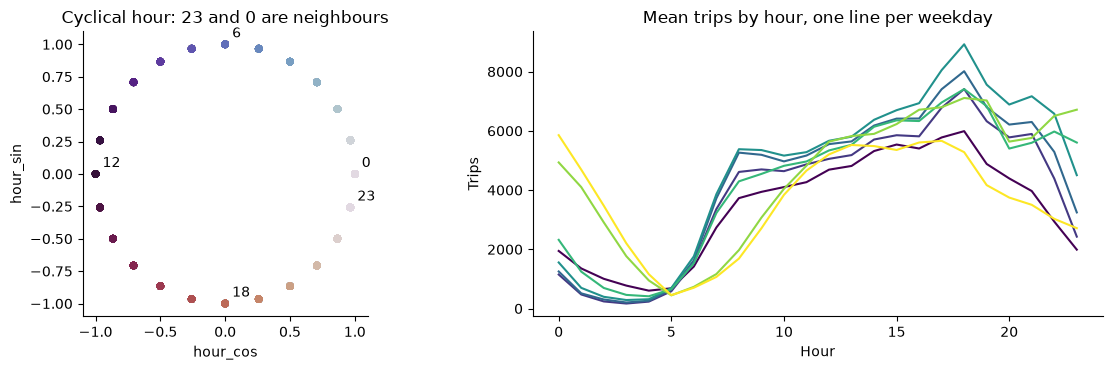

In [2]:
idx = demand.index
HOLIDAYS = pd.to_datetime(["2024-01-01", "2024-01-15", "2024-02-19"])          # New Year, MLK Day, Presidents' Day

def calendar(idx: pd.DatetimeIndex) -> pd.DataFrame:
    f = pd.DataFrame(index=idx)
    f["hour"] = idx.hour
    f["dow"] = idx.day_of_week
    f["weekend"] = (idx.day_of_week >= 5).astype(int)
    f["holiday"] = idx.normalize().isin(HOLIDAYS).astype(int)
    f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * idx.hour / 24), np.cos(2 * np.pi * idx.hour / 24)
    f["dow_sin"], f["dow_cos"] = np.sin(2 * np.pi * idx.day_of_week / 7), np.cos(2 * np.pi * idx.day_of_week / 7)
    return f

cal = calendar(idx)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.scatter(cal["hour_cos"], cal["hour_sin"], c=cal["hour"], cmap="twilight", s=20)
for h in [0, 6, 12, 18, 23]:
    ax1.annotate(str(h), (np.cos(2 * np.pi * h / 24), np.sin(2 * np.pi * h / 24)), xytext=(5, 5), textcoords="offset points")
ax1.set(aspect="equal", title="Cyclical hour: 23 and 0 are neighbours", xlabel="hour_cos", ylabel="hour_sin")
demand.groupby([idx.day_of_week, idx.hour]).mean().unstack(0).plot(ax=ax2, legend=False, cmap="viridis")
ax2.set(title="Mean trips by hour, one line per weekday", xlabel="Hour", ylabel="Trips")
plt.tight_layout()
plt.show()

## 2. Lags and Rolling Windows from the Past Only

A **lag** is a past value of the target (`shift(k)`); a **rolling window** summarises recent history. The forecasting task here: predict demand **24 hours ahead**, so every feature must be known 24 hours before the target hour. That means lags of at least 24 hours, and rolling windows that end at least 24 hours before.

In [3]:
H = 24                                                                  # forecast horizon in hours

def history(s: pd.Series, horizon: int = H) -> pd.DataFrame:
    past = s.shift(horizon)                                             # the most recent value known at prediction time
    f = pd.DataFrame(index=s.index)
    f["lag_24h"] = past
    f["lag_168h"] = s.shift(168)                                        # same hour last week
    f["roll_mean_24h"] = past.rolling(24).mean()
    f["roll_mean_7d"] = past.rolling(168).mean()
    f["roll_std_24h"] = past.rolling(24).std()
    return f

hist = history(demand)
print(hist.iloc[168:171].round(1))

                     lag_24h  lag_168h  roll_mean_24h  roll_mean_7d  \
2024-01-08 00:00:00   3813.0    6500.0         3995.6           NaN   
2024-01-08 01:00:00   2696.0    7233.0         3993.8           NaN   
2024-01-08 02:00:00   1876.0    6107.0         3996.4           NaN   

                     roll_std_24h  
2024-01-08 00:00:00        2112.5  
2024-01-08 01:00:00        2113.6  
2024-01-08 02:00:00        2110.9  


## 3. Time-Ordered Evaluation and Feature Groups

In [4]:
data = pd.concat([cal, hist], axis=1).assign(y=demand).iloc[168:]           # drop the first week (lags undefined)
tscv = TimeSeriesSplit(n_splits=5, test_size=24 * 5)                         # five consecutive 5-day test windows

def mae(cols, model):
    return -cross_val_score(model, data[cols], data["y"], cv=tscv, scoring="neg_mean_absolute_error").mean()

gbm = HistGradientBoostingRegressor(random_state=RNG)
groups = {
    "hour + dow (raw numbers)": ["hour", "dow"],
    "+ weekend, holiday": ["hour", "dow", "weekend", "holiday"],
    "+ lags": ["hour", "dow", "weekend", "holiday", "lag_24h", "lag_168h"],
    "+ rolling windows": ["hour", "dow", "weekend", "holiday", "lag_24h", "lag_168h", "roll_mean_24h", "roll_mean_7d", "roll_std_24h"],
}
res = {name: mae(cols, gbm) for name, cols in groups.items()}
lin_raw = mae(["hour", "dow"], make_pipeline(StandardScaler(), RidgeCV()))
lin_cyc = mae(["hour_sin", "hour_cos", "dow_sin", "dow_cos", "weekend"], make_pipeline(StandardScaler(), RidgeCV()))
print("gradient boosting MAE:", {k: round(v) for k, v in res.items()})
print(f"linear model: raw hour/dow MAE {lin_raw:.0f} | cyclical encodings MAE {lin_cyc:.0f}")
naive = (data["y"] - data["lag_168h"]).abs().iloc[-24 * 25:].mean()
print(f"baseline 'same hour last week' MAE on the last 25 days: {naive:.0f}")

gradient boosting MAE: {'hour + dow (raw numbers)': 414, '+ weekend, holiday': 399, '+ lags': 451, '+ rolling windows': 544}
linear model: raw hour/dow MAE 1466 | cyclical encodings MAE 1045
baseline 'same hour last week' MAE on the last 25 days: 509


Cyclical encodings help the linear model, which cannot bend a straight line around midnight; tree models split raw hours freely.

**Surprise:** the lag and rolling features make the gradient-boosting model **worse** here. Calendar features alone already capture the strong daily and weekly pattern. With only seven weeks of history, the early folds train on very few weeks, and lagged values carry last week's special days (holidays, the post-New-Year dip, a snowstorm) into the forecast. Lags and rolling windows pay off with longer history, when the overall level of demand drifts, or for shorter forecast horizons. Measure, do not assume.

## 4. The Centred-Window Leak

A rolling mean **centred** on the current hour (`rolling(24, center=True)`) uses the next 12 hours, which are unknown at prediction time. It looks great in evaluation and cannot be computed in production.

honest features MAE 544 | with a centred window MAE 418  <- impossible in production


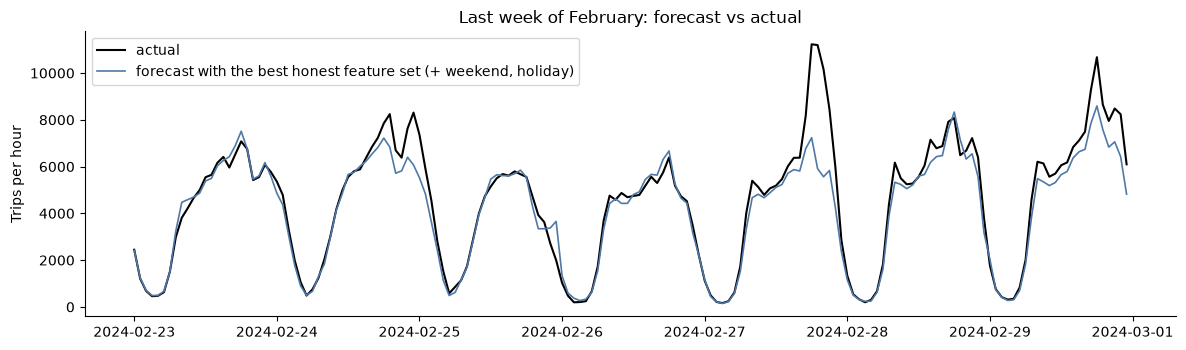

In [5]:
data_leak = data.assign(roll_centered=demand.rolling(24, center=True).mean())
cols_leak = groups["+ rolling windows"] + ["roll_centered"]
leak_mae = -cross_val_score(gbm, data_leak[cols_leak].dropna(), data_leak.dropna()["y"], cv=tscv, scoring="neg_mean_absolute_error").mean()
print(f"honest features MAE {res['+ rolling windows']:.0f} | with a centred window MAE {leak_mae:.0f}  <- impossible in production")

best_group = min(res, key=res.get)                                  # the feature set with the lowest CV error
model = gbm.fit(data[groups[best_group]].iloc[:-24 * 7], data["y"].iloc[:-24 * 7])
last_week = data.iloc[-24 * 7:]
pred = model.predict(last_week[groups[best_group]])
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(last_week.index, last_week["y"], color="black", lw=1.5, label="actual")
ax.plot(last_week.index, pred, color="#4E79A7", lw=1.2, label=f"forecast with the best honest feature set ({best_group})")
ax.set(title="Last week of February: forecast vs actual", ylabel="Trips per hour")
ax.legend()
plt.tight_layout()
plt.show()

*Insight: Build temporal features as "what was known at prediction time": calendar facts, lags at least as long as the forecast horizon, and rolling windows that end before the prediction. Evaluate with time-ordered splits, and treat any feature that makes the model suspiciously good as a leak until proven otherwise.*

## Real-World Use Case or Analogy

Temporal features are like a **weather forecaster's notes**: the season (calendar), yesterday's weather (lag), and the last week's average (rolling window). A forecaster who peeks at tomorrow's newspaper would be perfect and useless.

Energy companies, retailers and ride-hailing platforms forecast demand with exactly these features before moving to dedicated forecasting models (M17); "feature leakage from the future" is the most common reason why such forecasts disappoint in production.